# 📈 Scraping Data Historis Harga Saham (OHLCV)
## 7 Emiten LQ45 Sektor Energi — Yahoo Finance

**Tesis**: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi (LQ45)
Berdasarkan Analisis Sentimen Menggunakan Metode XGBoost dan LSTM

**Penulis**: Ilda Nurida (NRP 6032251068)
**Pembimbing**: Dr. Ir. Ahmad Saikhu, S.Si, MT.

---

### Tujuan Notebook
1. Mengunduh data historis **OHLCV** (Open, High, Low, Close, Volume) untuk 7 emiten sektor energi LQ45: **ADRO, ADMR, ITMG, PTBA, MEDC, AKRA, PGAS**
2. Menyediakan **gambaran umum penelitian** (tren harga penutupan) untuk Bab 1 / Bab 4
3. Menjadi **data dasar** untuk:
   - Perhitungan *Log Return* dan *Volatilitas Return* (Variabel **Y**)
   - Ekstraksi fitur teknikal **X1** (RSI, Moving Average, Stochastic Oscillator)

### Periode Data
**Januari 2022 – Mei 2026** (sesuai batasan penelitian)

### Catatan
- Data bersifat *time series* → **tidak dilakukan random shuffle**
- Output disimpan dalam 2 format: *long format* (semua OHLCV) dan *wide format* (Close saja, untuk gambaran umum)


## 1. Import Library

In [12]:
!pip install -q yfinance pandas numpy matplotlib

import os
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')


[notice] A new release of pip available: 22.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Konfigurasi Parameter

Mendefinisikan:
- Rentang waktu pengambilan data
- Daftar 6 emiten sektor energi LQ45 beserta kode ticker Yahoo Finance
- Folder output (disesuaikan dengan struktur folder proyek)


In [13]:
from pathlib import Path

# ── Periode penelitian ───────────────────────────────────────────────────────
START_DATE   = '2022-01-01'   # awal periode penelitian (inklusif)
END_DATE     = '2026-06-18'   # akhir periode penelitian (untuk judul/teks)
# Parameter `end` pada yf.download bersifat EKSKLUSIF -> ditambah 1 hari
# agar hari bursa terakhir (29-31 Mei 2026) ikut terambil dengan lengkap.
DOWNLOAD_END = '2026-06-18'

# ── Daftar 7 emiten LQ45 sektor energi ───────────────────────────────────────
EMITEN = {
    'ADRO': 'ADRO.JK',
    'ADMR': 'ADMR.JK',
    'ITMG': 'ITMG.JK',
    'PTBA': 'PTBA.JK',
    'MEDC': 'MEDC.JK',
    'AKRA': 'AKRA.JK',
    'PGAS': 'PGAS.JK',
}

NAMA_PERUSAHAAN = {
    'ADRO': 'Adaro Energy Indonesia Tbk',
    'ADMR': 'Adaro Minerals Indonesia Tbk',
    'ITMG': 'Indo Tambangraya Megah Tbk',
    'PTBA': 'Bukit Asam Tbk',
    'MEDC': 'Medco Energi Internasional Tbk',
    'AKRA': 'AKR Corporindo Tbk',
    'PGAS': 'Perusahaan Gas Negara Tbk',
}

URUTAN_EMITEN = list(EMITEN.keys())

# ── Direktori output (relatif terhadap 01_scraping_data/harga_saham/) ────────
OUTPUT_DIR_RAW = Path('../../03_dataset/raw')
OUTPUT_DIR_DASHBOARD = Path('../../dashboard/data')

for d in (OUTPUT_DIR_RAW, OUTPUT_DIR_DASHBOARD):
    d.mkdir(parents=True, exist_ok=True)

FILE_RAW   = 'harga_saham_raw.csv'
FILE_CLOSE = 'harga_penutupan_close.csv'
FILE_GAMBAR = 'gambar_4_1_harga_penutupan.png'

# ── Styling grafik: Times New Roman (standar penulisan tesis) ────────────────
plt.rcParams.update({
    'font.family'    : 'Times New Roman',
    'font.size'      : 11,
    'axes.titlesize' : 11,
    'axes.labelsize' : 10,
    'figure.dpi'     : 110,
    'axes.grid'      : True,
    'grid.alpha'     : 0.3,
})

# ── Ringkasan konfigurasi ────────────────────────────────────────────────────
print("=" * 70)
print("  KONFIGURASI PENELITIAN")
print("=" * 70)
print(f"  Periode data    : {START_DATE} s/d {END_DATE}")
print(f"  Sumber data     : Yahoo Finance (library yfinance)")
print(f"  Jumlah emiten   : {len(EMITEN)}")
for kode in EMITEN:
    print(f"    - {kode:5s} ({EMITEN[kode]:8s}) - {NAMA_PERUSAHAAN[kode]}")
print("-" * 70)
print(f"  Output raw      : {OUTPUT_DIR_RAW.resolve()}")
print(f"  Output dashboard: {OUTPUT_DIR_DASHBOARD.resolve()}")
print("=" * 70)

  KONFIGURASI PENELITIAN
  Periode data    : 2022-01-01 s/d 2026-06-18
  Sumber data     : Yahoo Finance (library yfinance)
  Jumlah emiten   : 7
    - ADRO  (ADRO.JK ) - Adaro Energy Indonesia Tbk
    - ADMR  (ADMR.JK ) - Adaro Minerals Indonesia Tbk
    - ITMG  (ITMG.JK ) - Indo Tambangraya Megah Tbk
    - PTBA  (PTBA.JK ) - Bukit Asam Tbk
    - MEDC  (MEDC.JK ) - Medco Energi Internasional Tbk
    - AKRA  (AKRA.JK ) - AKR Corporindo Tbk
    - PGAS  (PGAS.JK ) - Perusahaan Gas Negara Tbk
----------------------------------------------------------------------
  Output raw      : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw
  Output dashboard: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\dashboard\data


## 3. Download Data OHLCV per Emiten

Mengunduh data harian (`Open`, `High`, `Low`, `Close`, `Volume`) untuk setiap emiten
menggunakan `yfinance`. Kolom `Adj Close` tidak digunakan karena `auto_adjust=True`
sudah menyesuaikan harga Close secara otomatis.


In [14]:
print("=" * 80)
print("       MENGUNDUH DATA HISTORIS HARGA SAHAM (OHLCV)")
print(f"       Periode: {START_DATE} s/d {DOWNLOAD_END}")
print("=" * 80)

KOLOM_RAW = ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
raw_dict = {}

for kode, ticker in EMITEN.items():
    try:
        df = yf.download(
            ticker,
            start=START_DATE,
            end=DOWNLOAD_END,
            auto_adjust=False,   # tetap False agar Close & Adj Close keduanya ada
            progress=False
        )

        if df.empty:
            print(f"⚠️ {kode}: data kosong")
            continue

        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)

        df = df.reset_index()
        df.columns = [str(c) for c in df.columns]
        df = df[KOLOM_RAW].copy()

        # Metadata
        df['Kode_Emiten'] = kode
        df['Nama_Perusahaan'] = NAMA_PERUSAHAAN[kode]

        # ============================================================
        # PRICE UNTUK MODEL → WAJIB ADJ CLOSE
        # ============================================================
        df['Price_Model'] = df['Adj Close']

        # Audit corporate action
        ratio_std = (df['Close'] / df['Adj Close']).std()
        df['Corporate_Action_Flag'] = ratio_std > 0.001

        # Return ekstrem
        log_return_close = np.log(df['Close']).diff()
        extreme_dates = df.loc[
            log_return_close.abs() > 0.20,
            'Date'
        ].dt.strftime('%Y-%m-%d').tolist()

        raw_dict[kode] = df

        print(
            f"✅ {kode:<5} | "
            f"{len(df):4d} rows | "
            f"CorpAction={ratio_std:.4f}"
        )

        if extreme_dates:
            print(f"   Extreme return dates: {extreme_dates}")

    except Exception as e:
        print(f"❌ ERROR {kode}: {e}")

print("-" * 80)

if raw_dict:
    df_raw = (
        pd.concat(raw_dict.values(), ignore_index=True)
        .sort_values(['Kode_Emiten', 'Date'])
        .reset_index(drop=True)
    )

    PATH_OUTPUT_RAW = OUTPUT_DIR_RAW / FILE_RAW
    df_raw.to_csv(PATH_OUTPUT_RAW, index=False, encoding='utf-8-sig')

    print("💾 Data mentah berhasil disimpan")
    print(f"Total baris : {len(df_raw):,}")
    print(f"Total emiten: {df_raw['Kode_Emiten'].nunique()}")

else:
    print("❌ Tidak ada data tersimpan")

print("=" * 80)

       MENGUNDUH DATA HISTORIS HARGA SAHAM (OHLCV)
       Periode: 2022-01-01 s/d 2026-06-18
✅ ADRO  | 1065 rows | CorpAction=0.7007
   Extreme return dates: ['2024-11-28', '2024-11-29']
✅ ADMR  | 1065 rows | CorpAction=0.0233
   Extreme return dates: ['2022-01-04', '2022-01-05', '2022-01-06', '2022-01-07', '2022-01-10', '2022-01-11', '2022-01-12', '2022-03-02', '2025-10-08']
✅ ITMG  | 1065 rows | CorpAction=0.3462
✅ PTBA  | 1065 rows | CorpAction=0.4192
✅ MEDC  | 1065 rows | CorpAction=0.0597
✅ AKRA  | 1065 rows | CorpAction=0.1208
   Extreme return dates: ['2025-04-10']
✅ PGAS  | 1065 rows | CorpAction=0.1644
--------------------------------------------------------------------------------
💾 Data mentah berhasil disimpan
Total baris : 7,455
Total emiten: 7


## 4. Pemeriksaan Kualitas Data

In [15]:
print('=' * 80)
print('                       PEMERIKSAAN KUALITAS DATA')
print('=' * 80)
print(f'  {"Emiten":8s} {"Observasi":>10s}   {"Tanggal Awal":>12s}   {"Tanggal Akhir":>13s}')
print('  ' + '-' * 60)

total_missing  = 0
total_duplikat = 0

for kode, df_e in raw_dict.items():
    # Menghitung missing value pada kolom target (KOLOM_RAW menggunakan 'Date')
    total_missing  += int(df_e[KOLOM_RAW].isna().sum().sum())
    # Menghitung duplikasi berdasarkan kolom tanggal bursa ('Date')
    total_duplikat += int(df_e.duplicated(subset='Date').sum())
    
    print(f'  {kode:8s} {len(df_e):>10,d}   '
          f'{str(df_e["Date"].min().date()):>12s}   '
          f'{str(df_e["Date"].max().date()):>13s}')

print('  ' + '-' * 60)
print(f'  Total observasi seluruh emiten : {len(df_raw):,}')
print(f'  Lokasi file yang diperiksa     : {OUTPUT_DIR_RAW / FILE_RAW}')

# ── Status akhir kualitas dataset ────────────────────────────────────────────
if total_missing == 0 and total_duplikat == 0:
    print('\n  ✅ STATUS: DATASET BERSIH — Tidak ditemukan missing value maupun')
    print(f'     duplikasi pada file {FILE_RAW}. Data siap digunakan')
    print('     untuk tahap pemrosesan berikutnya.')
else:
    print(f'\n  ⚠️  STATUS: PERLU PENANGANAN — Ditemukan missing value: {total_missing}')
    print(f'     dan/atau duplikasi: {total_duplikat} pada file di {OUTPUT_DIR_RAW.resolve()}')
print('=' * 80)

                       PEMERIKSAAN KUALITAS DATA
  Emiten    Observasi   Tanggal Awal   Tanggal Akhir
  ------------------------------------------------------------
  ADRO          1,065     2022-01-03      2026-06-17
  ADMR          1,065     2022-01-03      2026-06-17
  ITMG          1,065     2022-01-03      2026-06-17
  PTBA          1,065     2022-01-03      2026-06-17
  MEDC          1,065     2022-01-03      2026-06-17
  AKRA          1,065     2022-01-03      2026-06-17
  PGAS          1,065     2022-01-03      2026-06-17
  ------------------------------------------------------------
  Total observasi seluruh emiten : 7,455
  Lokasi file yang diperiksa     : ..\..\03_dataset\raw\harga_saham_raw.csv

  ✅ STATUS: DATASET BERSIH — Tidak ditemukan missing value maupun
     duplikasi pada file harga_saham_raw.csv. Data siap digunakan
     untuk tahap pemrosesan berikutnya.


## 5. Hasil Scraping Seluruh Emiten (Tabel 4.1)

Menggabungkan data seluruh emiten menjadi satu tabel `harga_saham_raw`
dengan struktur *long format* — setiap baris merepresentasikan satu hari
perdagangan untuk satu emiten. Data diurutkan berdasarkan `Emiten` lalu `Date`
agar urutan kronologis tetap terjaga (penting untuk Time-Series Split).


In [ ]:
EMITEN_CONTOH = 'ADRO'   # Ganti kode di sini bila ingin contoh emiten lain

# ── 1. Ambil 10 baris pertama dari dictionary raw_dict hasil unduhan ────────
tabel_4_1 = raw_dict[EMITEN_CONTOH].head(10).copy()

# Format kolom tanggal menjadi format standar Indonesia (DD/MM/YYYY) untuk Bab 4
tabel_4_1['Date'] = pd.to_datetime(tabel_4_1['Date']).dt.strftime('%d/%m/%Y')
tabel_4_1 = tabel_4_1.reset_index(drop=True)
tabel_4_1.index = tabel_4_1.index + 1        # Penomoran baris dimulai dari 1
tabel_4_1.index.name = 'No'

# ── 2. Simpan data MENTAH (nilai numerik asli, belum diformat) ─────────────
FILE_TABEL_4_1  = 'tabel_4_1_contoh_data_mentah.csv'
PATH_OUTPUT_4_1 = OUTPUT_DIR_RAW / FILE_TABEL_4_1
tabel_4_1.to_csv(PATH_OUTPUT_4_1, encoding='utf-8-sig')

# ── 3. Buat SALINAN khusus untuk tampilan (format angka gaya Indonesia) ────
#     Memakai .copy() supaya tabel_4_1 asli (numerik) tidak ikut berubah —
#     dengan begini, cell ini aman dijalankan berulang kali (idempotent).
tabel_4_1_tampil = tabel_4_1.copy()
kolom_angka = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

for kol in kolom_angka:
    tabel_4_1_tampil[kol] = tabel_4_1_tampil[kol].apply(
        lambda x: '–' if pd.isna(x)
        else f'{x:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
    )

# ── 4. Ringkasan info penyimpanan ──────────────────────────────────────────
print(f' Tabel 4.1 Contoh Data Mentah Hasil Scraping Saham ({EMITEN_CONTOH} — ')
print(f'           {NAMA_PERUSAHAAN[EMITEN_CONTOH]}, 10 observasi pertama)')
print(f' Sumber: Yahoo Finance, diolah penulis (2026)')
print('-' * 80)
print(f' 💾 Tersimpan di : {PATH_OUTPUT_4_1.resolve()}')
print('=' * 80)

tabel_4_1_tampil   # Ekspresi terakhir → dirender rapi oleh Jupyter Notebook

## 6. Tabel Harga Penutupan (Close) — Wide Format

Tabel ini digunakan sebagai **gambaran umum penelitian** (Bab 1 / Bab 4),
menampilkan tren harga penutupan keenam emiten secara berdampingan
(baris = tanggal, kolom = emiten).


In [17]:
URUTAN_EMITEN = list(EMITEN.keys())

# ── Pivot long → wide: baris=Date, kolom=emiten, nilai=Adj Close ────────────
tab_adjclose = (df_raw.pivot_table(index='Date', columns='Kode_Emiten',
                                   values='Adj Close', aggfunc='first')
                      .reindex(columns=URUTAN_EMITEN)
                      .sort_index())

# ── Susun sampel: tanggal DD/MM/YYYY, harga bulat, head 5 + ⋮ + tail 5 ──────
tab_fmt = tab_adjclose.copy()

# Pastikan indeks berbentuk DatetimeIndex agar pemformatan tanggal aman
tab_fmt.index = pd.to_datetime(tab_fmt.index)
tab_fmt.index = tab_fmt.index.strftime('%d/%m/%Y')

tab_str = tab_fmt.apply(lambda kol: kol.map(
    lambda v: '–' if pd.isna(v) else f'{v:.0f}'))

elips  = pd.DataFrame([{c: '⋮' for c in tab_str.columns}], index=['⋮'])
sampel = pd.concat([tab_str.head(5), elips, tab_str.tail(5)])
sampel.index.name = 'Tanggal'
sampel.columns.name = None   # Tanpa label kelompok kolom — tampilan polos

# ── Simpan dua versi CSV (untuk Word & lampiran) ke OUTPUT_DIR_RAW ───────────
tab_lengkap = tab_adjclose.copy()
tab_lengkap.index = pd.to_datetime(tab_lengkap.index)
tab_lengkap.index = tab_lengkap.index.strftime('%d/%m/%Y')
tab_lengkap.index.name = 'Tanggal'

# Mengonversi format ke tipe integer yang mendukung nilai kosong (nullable integer)
tab_lengkap = tab_lengkap.round(0).astype('Int64')

# Menentukan file name dan path output baru
FILE_LENGKAP  = 'tabel_4_2_adjusted_close_LENGKAP.csv'
FILE_SAMPEL   = 'tabel_4_2_adjusted_close_SAMPEL.csv'
path_lengkap  = OUTPUT_DIR_RAW / FILE_LENGKAP
path_sampel   = OUTPUT_DIR_RAW / FILE_SAMPEL

# Simpan ke CSV
tab_lengkap.to_csv(path_lengkap, encoding='utf-8-sig')
sampel.to_csv(path_sampel, encoding='utf-8-sig')

# Format angka: pemisah ribuan "." dan 2 angka di belakang koma
fmt_num = lambda v: '–' if pd.isna(v) else f'{v:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

# Overwrite versi CSV agar konsisten dengan format yang diminta
tab_lengkap = tab_adjclose.copy()
tab_lengkap.index = pd.to_datetime(tab_lengkap.index).strftime('%d/%m/%Y')
tab_lengkap.index.name = 'Tanggal'
tab_lengkap = tab_lengkap.apply(lambda kol: kol.map(fmt_num))
tab_lengkap.to_csv(path_lengkap, encoding='utf-8-sig')

tab_str = tab_adjclose.copy()
tab_str.index = pd.to_datetime(tab_str.index).strftime('%d/%m/%Y')
tab_str = tab_str.apply(lambda kol: kol.map(fmt_num))

elips = pd.DataFrame([{c: '⋮' for c in tab_str.columns}], index=['⋮'])
sampel = pd.concat([tab_str.head(5), elips, tab_str.tail(5)])
sampel.index.name = 'Tanggal'
sampel.columns.name = None
sampel.to_csv(path_sampel, encoding='utf-8-sig')

tab_lengkap.columns.name = None
sampel.columns.name = None
print(' Tabel 4.2 Data Adjusted Closing Price Saham Tujuh Emiten Sektor Energi')
print(' Sumber: Yahoo Finance, diolah penulis (2026)')
print('-' * 80)
print(f' Total observasi (tabel lengkap): {len(tab_adjclose):,} hari bursa')
print(f' 💾 Berkas Lengkap : {path_lengkap.resolve()}')
print(f' 💾 Berkas Sampel  : {path_sampel.resolve()}')
print('=' * 80)

sampel   # Ekspresi terakhir → dirender rapi sebagai DataFrame Jupyter

 Tabel 4.2 Data Adjusted Closing Price Saham Tujuh Emiten Sektor Energi
 Sumber: Yahoo Finance, diolah penulis (2026)
--------------------------------------------------------------------------------
 Total observasi (tabel lengkap): 1,065 hari bursa
 💾 Berkas Lengkap : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\tabel_4_2_adjusted_close_LENGKAP.csv
 💾 Berkas Sampel  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\tabel_4_2_adjusted_close_SAMPEL.csv


,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
03/01/2022,"801,11","125,22","9.170,15","1.172,95","378,44","634,57","891,03"
04/01/2022,"777,45","168,82","9.310,33","1.186,13","384,99","611,29","891,03"
05/01/2022,"757,17","226,33","9.368,74","1.199,31","396,46","599,64","868,75"
06/01/2022,"777,45","281,99","9.170,15","1.186,13","399,73","605,46","859,20"
07/01/2022,"821,40","352,48","9.357,06","1.225,67","403,01","624,38","862,39"
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
10/06/2026,"2.300,00","1.540,00","22.000,00","2.617,92","1.163,54","1.240,00","1.540,00"
11/06/2026,"2.250,00","1.465,00","22.350,00","2.512,82","1.183,01","1.265,00","1.500,00"
12/06/2026,"2.280,00","1.575,00","23.475,00","2.503,26","1.192,75","1.250,00","1.530,00"


## 7. Tabel Harga Penutupan Awal & Akhir Periode (Tabel 4.2)

Menampilkan 5 hari pertama dan 5 hari terakhir periode penelitian sebagai
ilustrasi gambaran umum data pada laporan (Bab 1 / Bab 4).


In [18]:
# ── Susun tabel gabungan: head(N) + baris pemisah (...) + tail(N) ────────────
# Sesuai format Tabel 4.2 pada laporan tesis (satu tabel dengan baris pemisah)
# Format angka: 2 desimal dengan pemisah ribuan (contoh: 1,228.00)
N = 5
harga_close_fmt = tab_adjclose.copy()
for col in harga_close_fmt.columns:
    harga_close_fmt[col] = harga_close_fmt[col].apply(lambda x: f"{x:,.2f}")

tabel_4_2_display = pd.concat([
    harga_close_fmt.head(N),
    pd.DataFrame([['...'] * len(harga_close_fmt.columns)],
                  columns=harga_close_fmt.columns,
                  index=['...']),
    harga_close_fmt.tail(N)
])
tabel_4_2_display.index.name = 'Tanggal'

print("=" * 80)
tabel_4_2_display.index = [
    pd.to_datetime(idx).strftime('%d/%m/%Y') if idx != '...' else '...'
    for idx in tabel_4_2_display.index
]
print(f" TABEL 4.2 - HARGA PENUTUPAN / ADJUSTED CLOSE (Rp)")
print(f" {N} Hari Pertama dan {N} Hari Terakhir Periode Penelitian")
print("=" * 80)
display(tabel_4_2_display)

 TABEL 4.2 - HARGA PENUTUPAN / ADJUSTED CLOSE (Rp)
 5 Hari Pertama dan 5 Hari Terakhir Periode Penelitian


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
03/01/2022,801.11,125.22,"9,170.15","1,172.95",378.44,634.57,891.03
04/01/2022,777.45,168.82,"9,310.33","1,186.13",384.99,611.29,891.03
05/01/2022,757.17,226.33,"9,368.74","1,199.31",396.46,599.64,868.75
06/01/2022,777.45,281.99,"9,170.15","1,186.13",399.73,605.46,859.20
07/01/2022,821.40,352.48,"9,357.06","1,225.67",403.01,624.38,862.39
...,...,...,...,...,...,...,...
10/06/2026,"2,300.00","1,540.00","22,000.00","2,617.92","1,163.54","1,240.00","1,540.00"
11/06/2026,"2,250.00","1,465.00","22,350.00","2,512.82","1,183.01","1,265.00","1,500.00"
12/06/2026,"2,280.00","1,575.00","23,475.00","2,503.26","1,192.75","1,250.00","1,530.00"
15/06/2026,"2,320.00","1,660.00","23,375.00","2,503.26","1,180.00","1,225.00","1,575.00"


## 7. Statistik Deskriptif Harga Penutupan (Tabel 4.3)

In [19]:
KOLOM_HARGA = 'Close'

tabel_4_3 = (df_raw.groupby('Kode_Emiten')[KOLOM_HARGA]
                   .agg(Jumlah_Observasi='count',
                        Mean='mean',
                        Median='median',
                        Minimum='min',
                        Maksimum='max',
                        Std_Deviasi='std')
                   .reindex(URUTAN_EMITEN)
                   .round(2))

tabel_4_3_path = OUTPUT_DIR_RAW / 'tabel_4_3_statistik_deskriptif_close.csv'
tabel_4_3.to_csv(tabel_4_3_path, encoding='utf-8-sig')

print("Tabel 4.3 Statistik Deskriptif Harga Penutupan Saham")

tabel_4_3 = tabel_4_3.copy()

tabel_4_3["Jumlah_Observasi"] = tabel_4_3["Jumlah_Observasi"].map(
     lambda v: f"{int(v):,}".replace(",", ".")
)

for col in ["Mean", "Median", "Minimum", "Maksimum", "Std_Deviasi"]:
     tabel_4_3[col] = tabel_4_3[col].map(
          lambda v: f"{v:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
     )
print("Sumber: Yahoo Finance, diolah penulis (2026)")
print(f"Disimpan: {tabel_4_3_path}")
tabel_4_3

Tabel 4.3 Statistik Deskriptif Harga Penutupan Saham
Sumber: Yahoo Finance, diolah penulis (2026)
Disimpan: ..\..\03_dataset\raw\tabel_4_3_statistik_deskriptif_close.csv


,Jumlah_Observasi,Mean,Median,Minimum,Maksimum,Std_Deviasi
Kode_Emiten,,,,,,
ADRO,1.065,"2.677,97","2.580,00","1.640,00","4.140,00","630,85"
ADMR,1.065,"1.396,89","1.345,00","135,00","2.990,00","394,98"
ITMG,1.065,"27.881,81","26.150,00","19.625,00","45.350,00","6.072,58"
PTBA,1.065,"2.998,97","2.810,00","2.170,00","4.630,00","579,88"
MEDC,1.065,"1.138,18","1.170,00","462,00","1.995,00","302,13"
AKRA,1.065,"1.319,29","1.330,00","695,00","1.850,00","218,25"
PGAS,1.065,"1.576,29","1.575,00","1.065,00","2.450,00","240,83"


## 8. Visualisasi Tren Harga Penutupan

Grafik *line chart* untuk melihat tren harga penutupan masing-masing emiten
selama periode penelitian — digunakan sebagai ilustrasi pada Bab 1 (latar belakang)
atau Bab 4 (gambaran umum data).


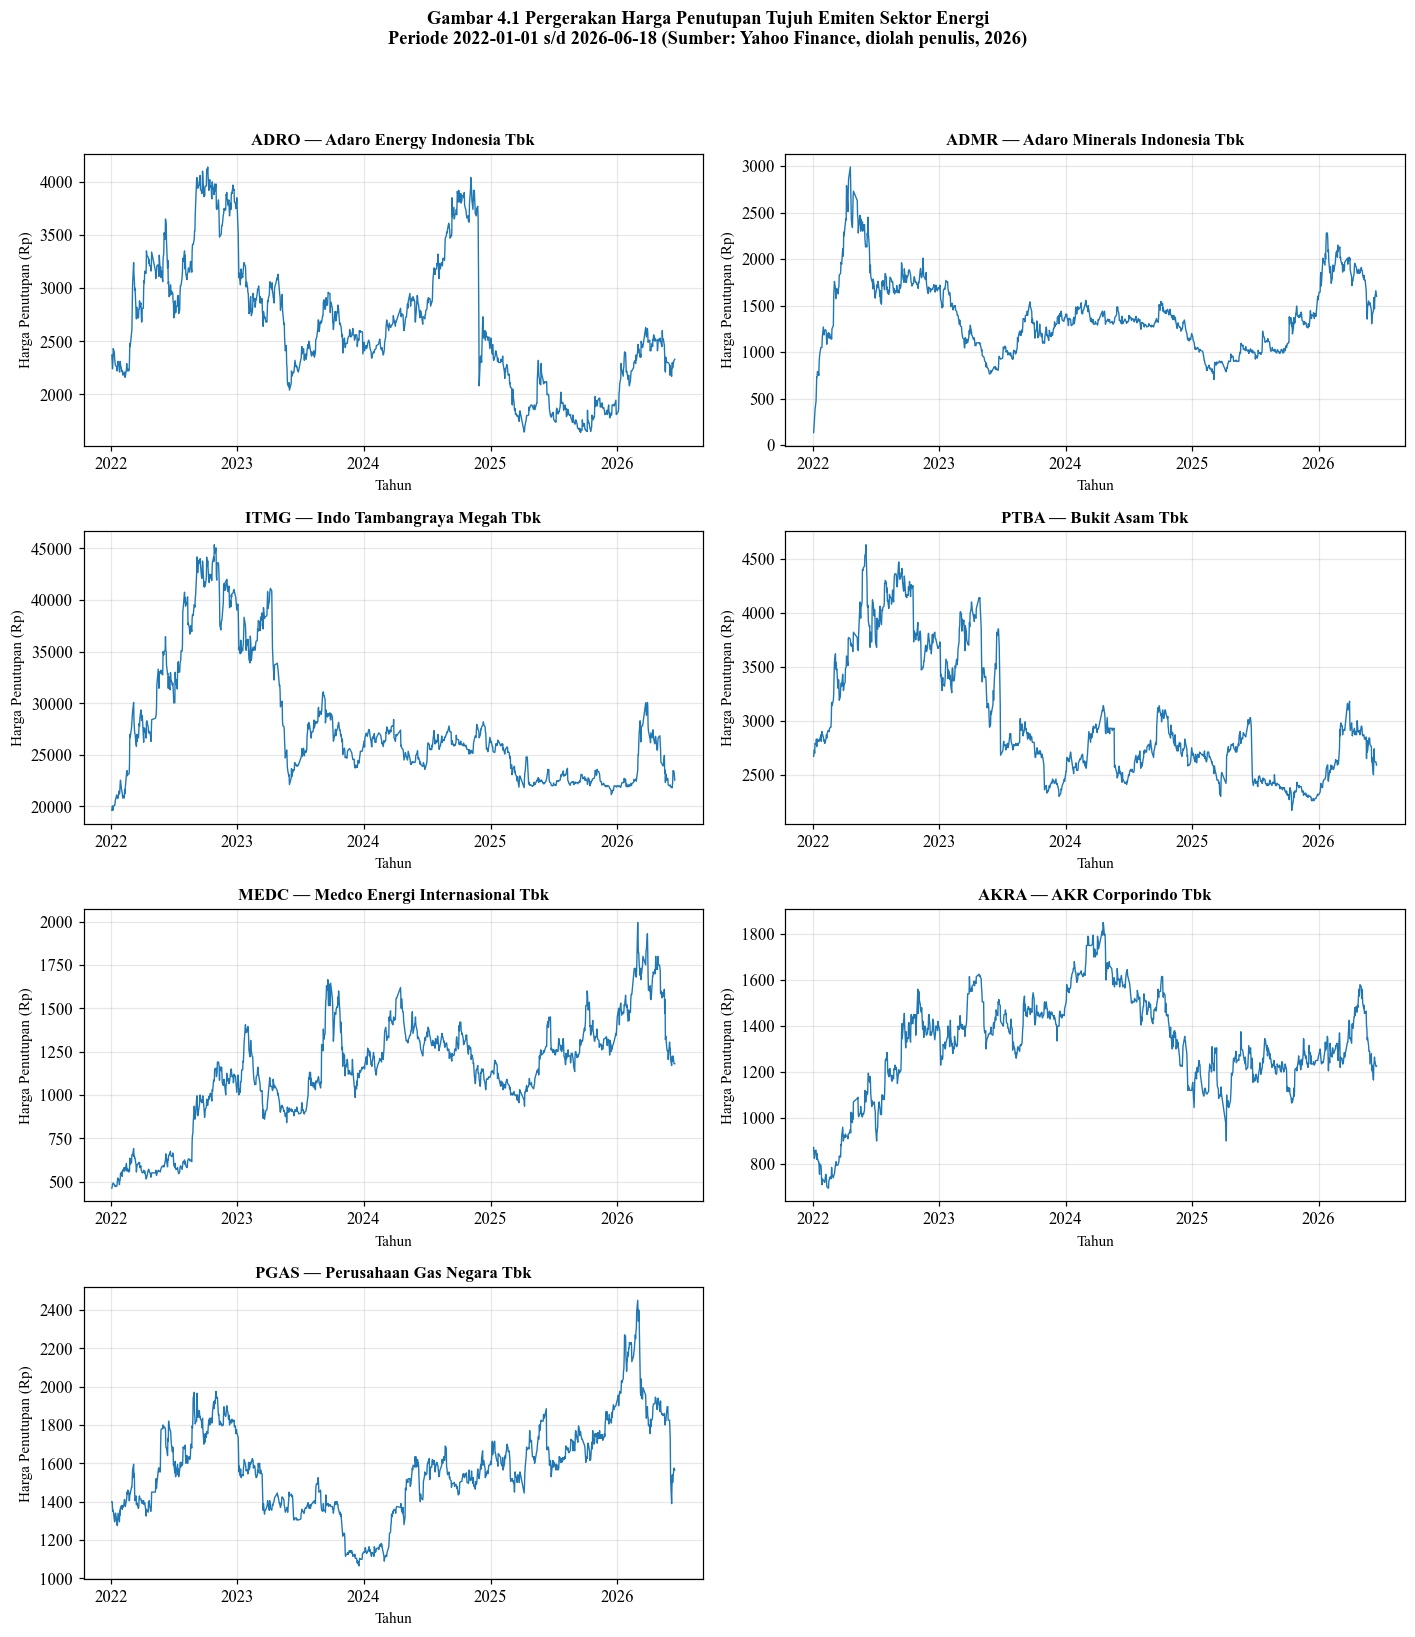

💾 Gambar berhasil disimpan!
   Lokasi Penyimpanan : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\gambar_4_1_harga_penutupan.png


In [20]:
fig, axes = plt.subplots(4, 2, figsize=(13, 15))
axes = axes.flatten()

KOLOM_HARGA = 'Close'  # Menggunakan harga penutupan nominal bursa

for i, kode in enumerate(URUTAN_EMITEN):
    # Filter data spesifik untuk masing-masing emiten
    sub = df_raw[df_raw['Kode_Emiten'] == kode].copy()
    
    # Pastikan kolom Date bertipe Datetime agar locator mdates.YearLocator() bekerja dengan benar
    sub['Date'] = pd.to_datetime(sub['Date'])
    
    ax = axes[i]
    ax.plot(sub['Date'], sub[KOLOM_HARGA], color='tab:blue', linewidth=0.9)
    
    # Sumbu-x: tampilkan TAHUN secara rapi di setiap panel bursa
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    
    # Kelengkapan anotasi grafik panel (Format Penulisan Tesis)
    ax.set_title(f'{kode} — {NAMA_PERUSAHAAN[kode]}', fontweight='bold', fontsize=11)
    ax.set_xlabel('Tahun', fontsize=10)
    ax.set_ylabel('Harga Penutupan (Rp)', fontsize=10)

# Sembunyikan panel ke-8 (indeks terakhir) karena hanya ada 7 emiten energi LQ45
axes[-1].axis('off')

# Menambahkan judul utama Gambar sesuai dengan standar penulisan Bab 4
fig.suptitle('Gambar 4.1 Pergerakan Harga Penutupan Tujuh Emiten Sektor Energi\n'
             f'Periode {START_DATE} s/d {END_DATE} (Sumber: Yahoo Finance, '
             'diolah penulis, 2026)',
             fontsize=12, fontweight='bold', y=0.99)

# Atur tata letak agar tidak saling tumpang tindih (overlap)
fig.tight_layout(rect=[0, 0, 1, 0.96])

# ── Simpan Gambar ke Folder Output Terpusat (Resolusi Tinggi untuk Tesis) ───
FILE_GAMBAR = 'gambar_4_1_harga_penutupan.png'
path_gambar = OUTPUT_DIR_RAW / FILE_GAMBAR

fig.savefig(path_gambar, dpi=300, bbox_inches='tight')
plt.show()

print('=' * 80)
print(f'💾 Gambar berhasil disimpan!')
print(f'   Lokasi Penyimpanan : {path_gambar.resolve()}')
print('=' * 80)

## 8. Output Notebook

| Nama File / Artifak | Direktori Lokasi Penyimpanan | Keterangan & Peruntukan Variabel |
| :--- | :--- | :--- |
| `harga_saham_raw.csv` | `/03_dataset/raw/`<br>`/dashboard/data/` | Data historis OHLCV dalam bentuk format memanjang (*long format*), bertindak sebagai pondasi **Input Fitur Dasar ($X_1$)**. |
| `harga_penutupan_close.csv` | `/03_dataset/raw/`<br>`/dashboard/data/` | Data matriks harga penutupan (*Close*) dalam format melebar (*wide format*) antar-emiten; digunakan untuk menyusun visualisasi gambaran umum tren pergerakan bursa. |
| `tren_harga_penutupan.png` | `/dashboard/data/` | Berkas visualisasi grafik tren pergerakan harga saham gabungan (berfungsi sebagai ilustrasi pendukung analisis dokumen Bab 1 atau Bab 4 tesis). |

### Langkah Selanjutnya (Pipeline Pemrosesan Data)

1. **`02_preprocessing/teknikal/`**
   * **Deskripsi Aktivitas**: Memuat file `harga_saham_raw.csv` dari folder dataset mentah, lalu melakukan transformasi kalkulasi deret waktu untuk menghitung *Log Return*, Volatilitas Return sebagai variabel **Target ($Y$)**, serta ekstraksi indikator teknikal utama meliputi *Relative Strength Index* (RSI), *Moving Average* (MA), dan *Stochastic Oscillator* sebagai komponen **Fitur Kuantitatif ($X_1$)**.
2. **`01_scraping_data/berita_sentimen/`**
   * **Deskripsi Aktivitas**: Menjalankan skrip penambangan data (*scraping*) teks berita keuangan dari berbagai portal berita nasional (seperti Detik, Kontan, dan Bisnis Indonesia) untuk wilayah tanggal bursa terkait. Teks berita ini kemudian diumpankan ke arsitektur deep learning **IndoBERT** untuk menghasilkan ekstraksi skor sentimen pasar sebagai **Fitur Tekstual ($X_2$)**.
3. **`05_integrasi_dataset.ipynb`**
   * **Deskripsi Aktivitas**: Melakukan konsolidasi akhir dengan menggabungkan (*merge*) matriks waktu secara presisi berdasarkan indeks tanggal (*time-index alignment*). Langkah ini menyatukan Fitur Kuantitatif ($X_1$), Fitur Sentimen Pasar ($X_2$), dan Target Nilai Volatilitas ($Y$) ke dalam satu *Master Dataset* yang siap dimasukkan ke dalam pemodelan XGBoost dan LSTM pada Bab 4.